# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import os
from IPython.display import display, Markdown

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')

def plot_ticker(ticker):
    results_dir = 'test_results'
    methods = ['DQN', 'Q_learning']
    colors = {'DQN': '#2ca02c', 'Q_learning': '#ff7f0e'}
    
    plt.figure(figsize=(14, 7))
    
    has_data = False
    all_dfs = {}
    
    for method in methods:
        filename = f"{ticker}_{method}_history.json"
        filepath = os.path.join(results_dir, filename)
        
        if os.path.exists(filepath):
            has_data = True
            with open(filepath, 'r') as f:
                data = json.load(f)
            
            df = pd.DataFrame(data)
            if not df.empty:
                df['date'] = pd.to_datetime(df['date'])
                all_dfs[method] = df
                
                # Calculate % return for normalization
                initial_val = df['portfolio_value'].iloc[0]
                df['return'] = (df['portfolio_value'] - initial_val) / initial_val * 100
                
                
                # Use dashed line for Fixed Q-table to show overlap
                linestyle = '--' if method == 'Fixed_Q_table' else '-'
                linewidth = 3.0 if method == 'Fixed_Q_table' else 2.5
                alpha = 0.8 if method == 'Fixed_Q_table' else 1.0
                
                plt.plot(df['date'], df['portfolio_value'], 
                         label=f"{method.replace('_', ' ')}", 
                         color=colors.get(method), 
                         linewidth=linewidth,
                         linestyle=linestyle,
                         alpha=alpha)
    
    if has_data:
        plt.title(f'{ticker} Strategy Comparison', fontsize=18, fontweight='bold')
        plt.xlabel('Date', fontsize=12)
        plt.ylabel('Portfolio Value ($)', fontsize=12)
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        # --- Display LLM Insights ---
        #display(Markdown(f"### 🧠 {ticker} Quarterly LLM Insights"))
        
        # Use DQN history (or whichever exists) to show insights
        best_method = 'DQN' if 'DQN' in all_dfs else list(all_dfs.keys())[0]
        history_df = all_dfs[best_method]
        
        '''
        if 'llm_analysis' in history_df.columns:
            # Group by duplicate analysis text to show one per quarter
            insights = history_df[history_df['llm_analysis'] != ""].drop_duplicates(subset=['llm_analysis'])
            
            for _, row in insights.iterrows():
                date_str = row['date'].strftime('%Y-%m-%d')
                analysis = row['llm_analysis']
                # Show first 500 chars + clean format
                display(Markdown(f"**{date_str}**: {analysis}"))
                display(Markdown("---"))
        else:
            print("⚠️ No LLM analysis text found in history. Ensure you've run the backtest with the latest code.")
            '''
    else:
        print(f"No data found for {ticker} in {results_dir}")

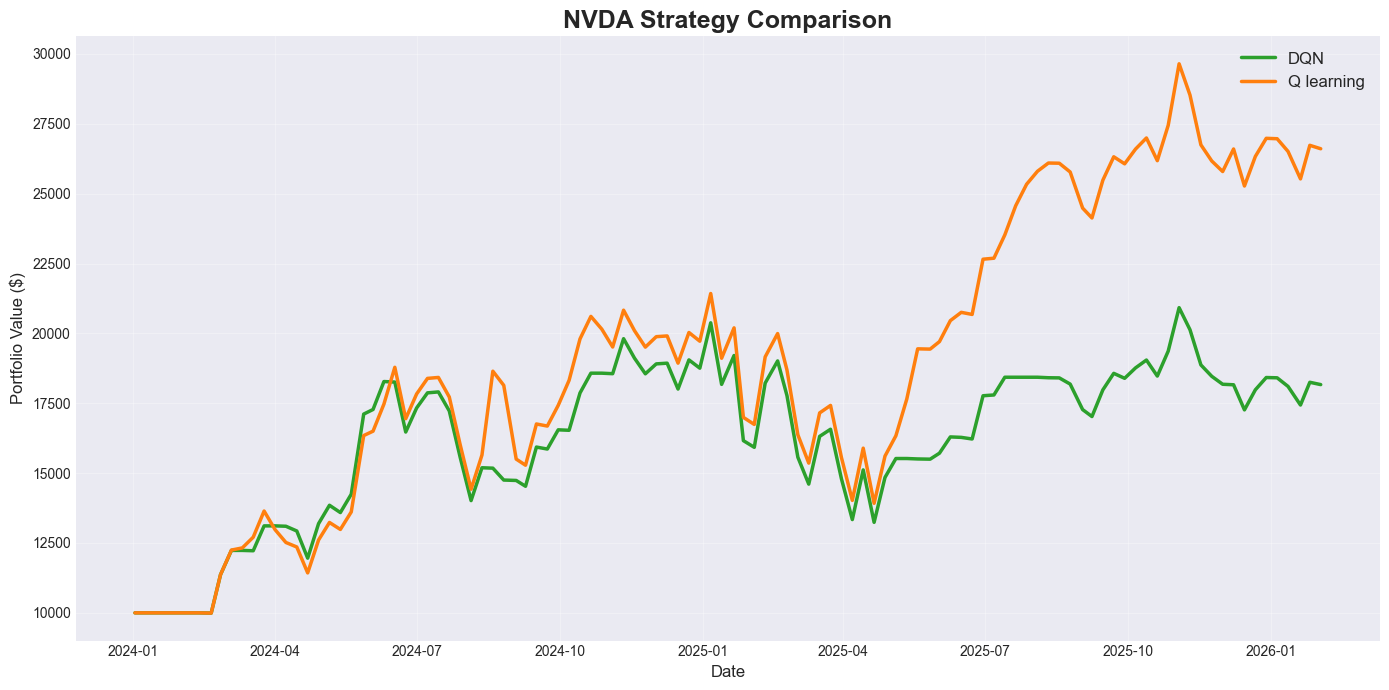

In [9]:
plot_ticker('NVDA')

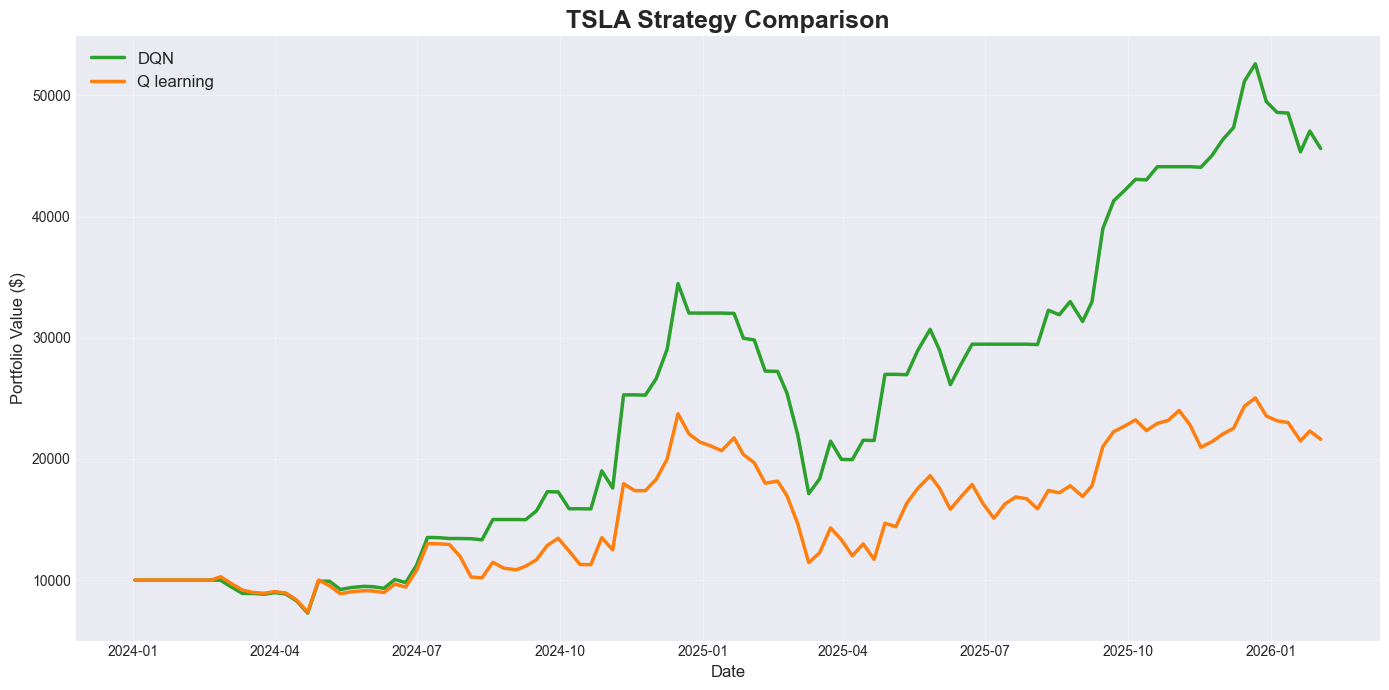

In [10]:
plot_ticker('TSLA')

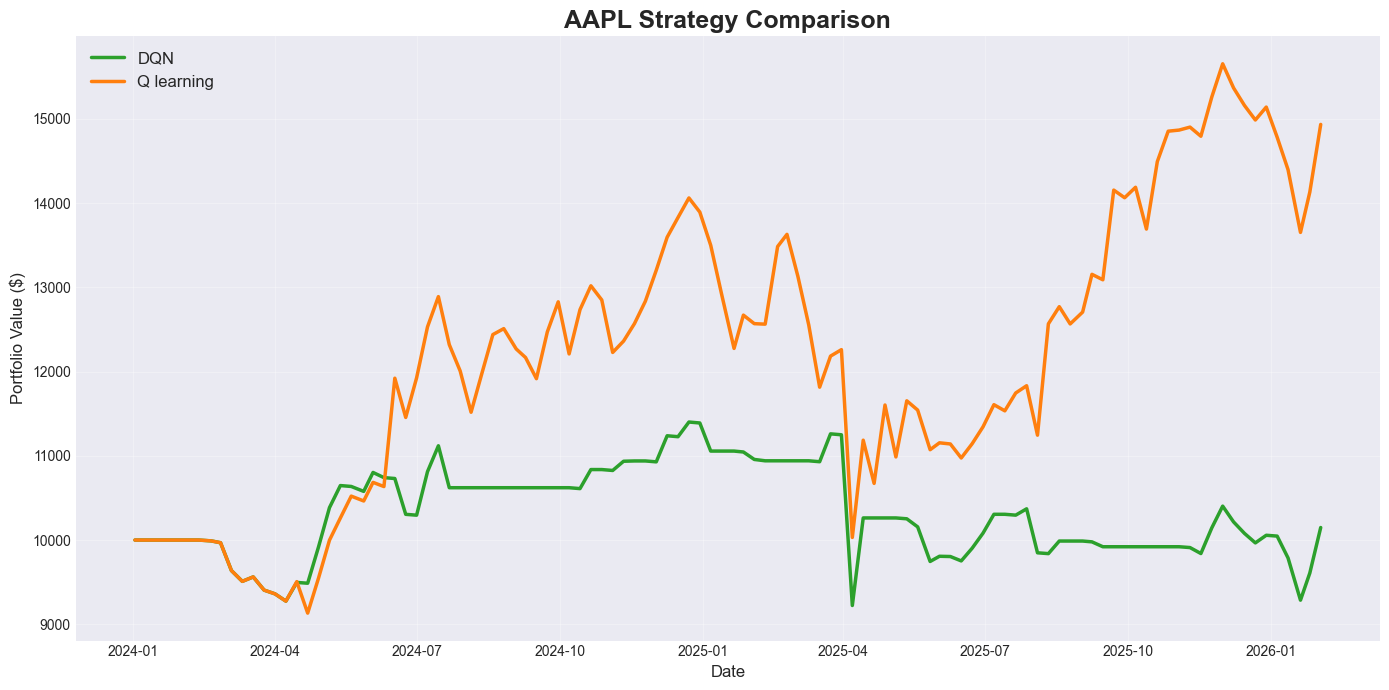

In [11]:
plot_ticker('AAPL')

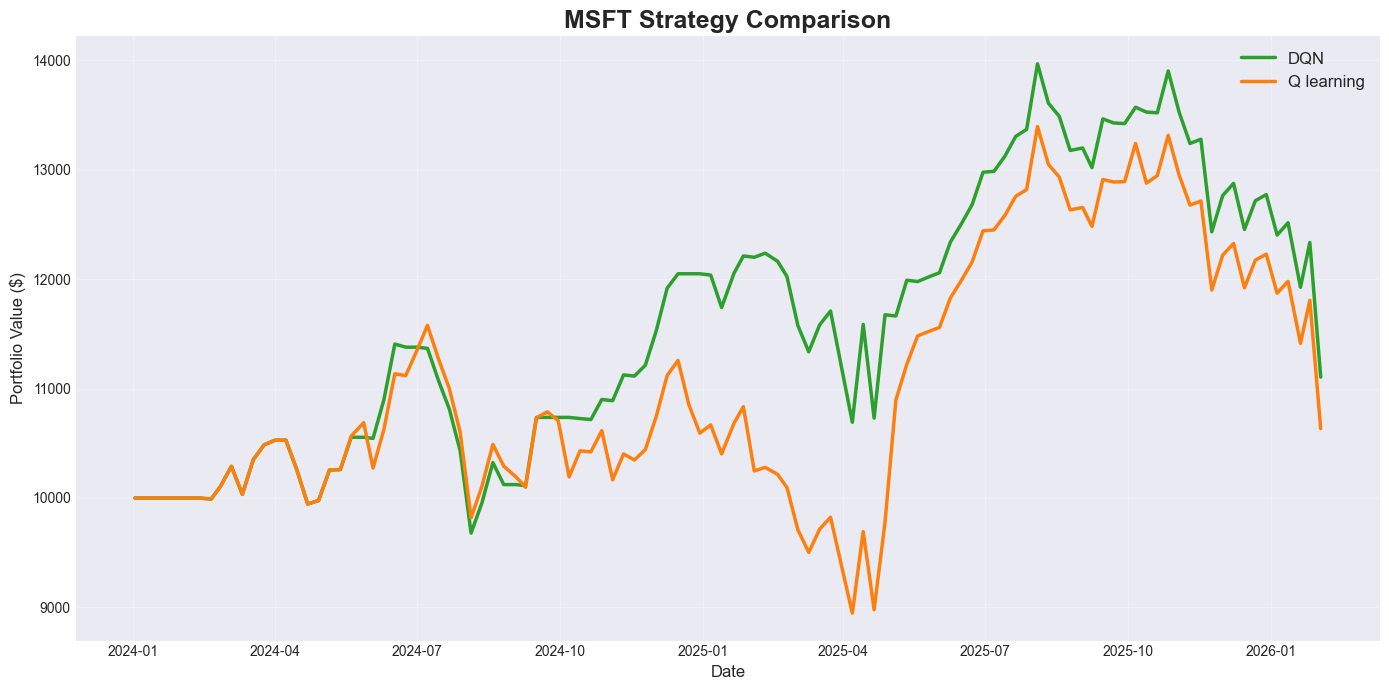

In [12]:
plot_ticker('MSFT')

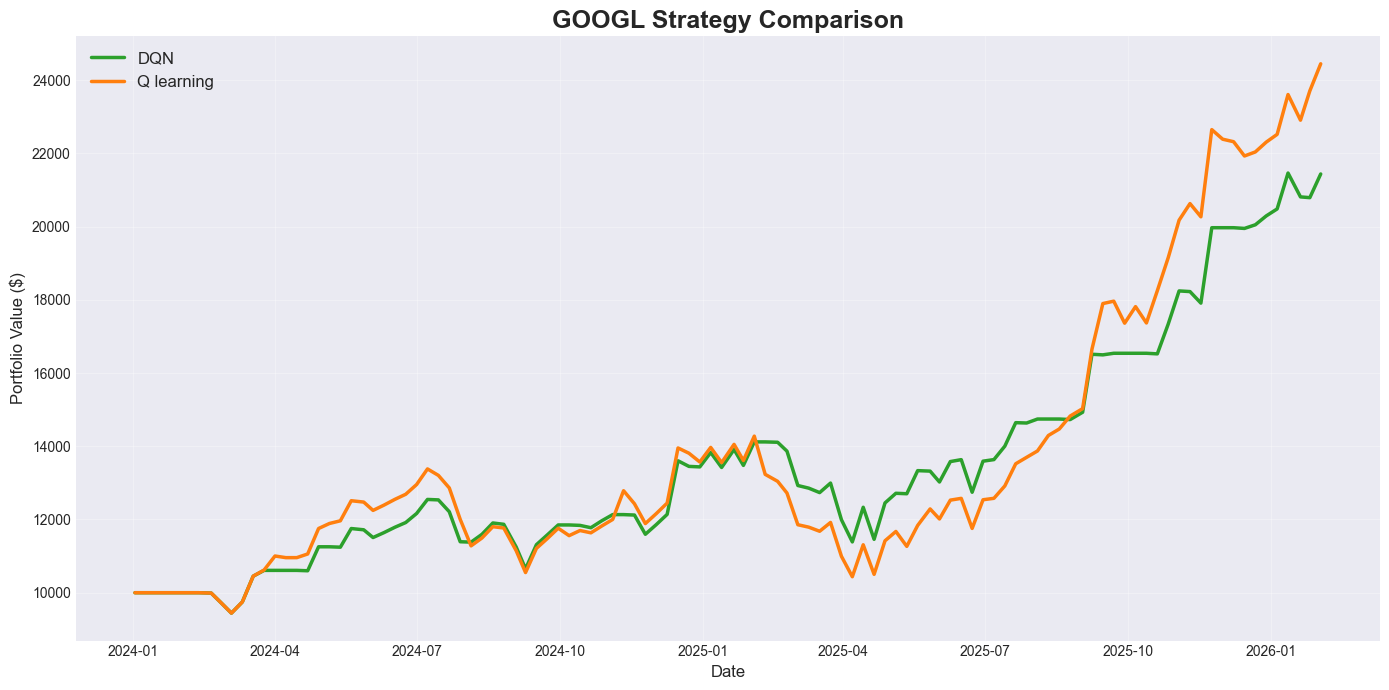

In [13]:
plot_ticker('GOOGL')

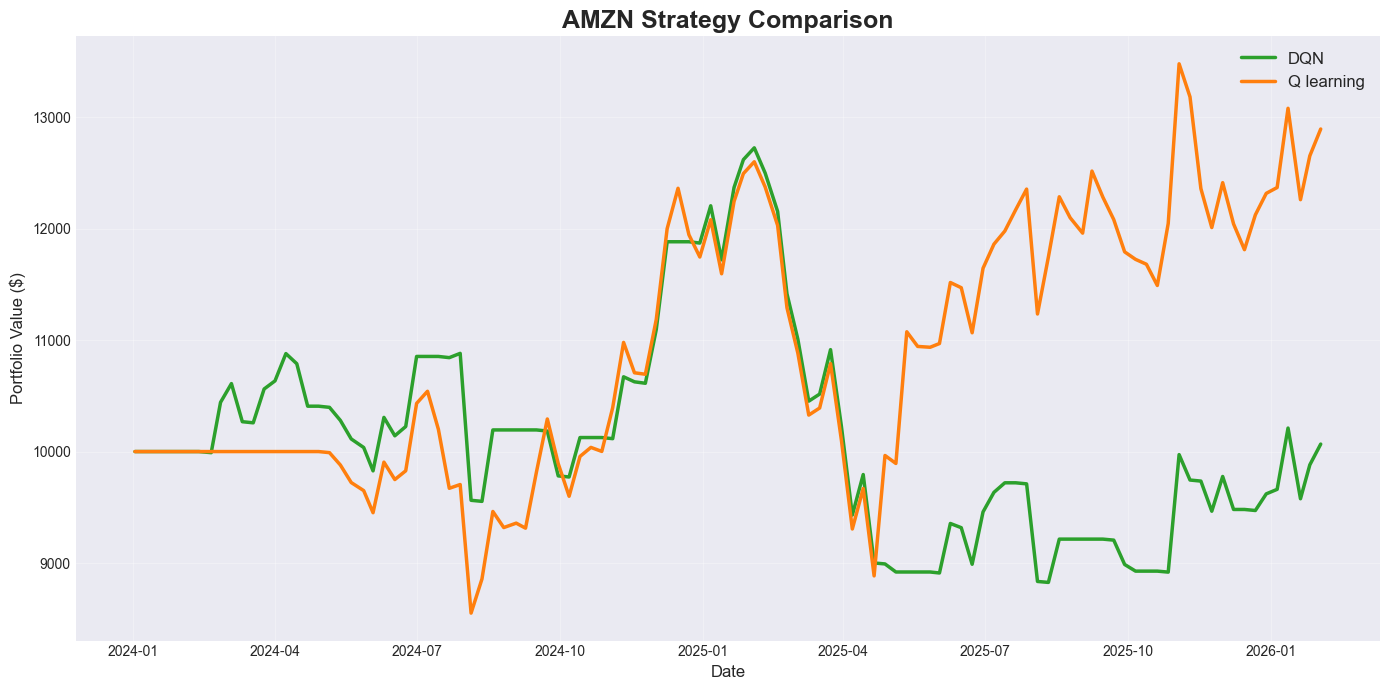

In [14]:
plot_ticker('AMZN')

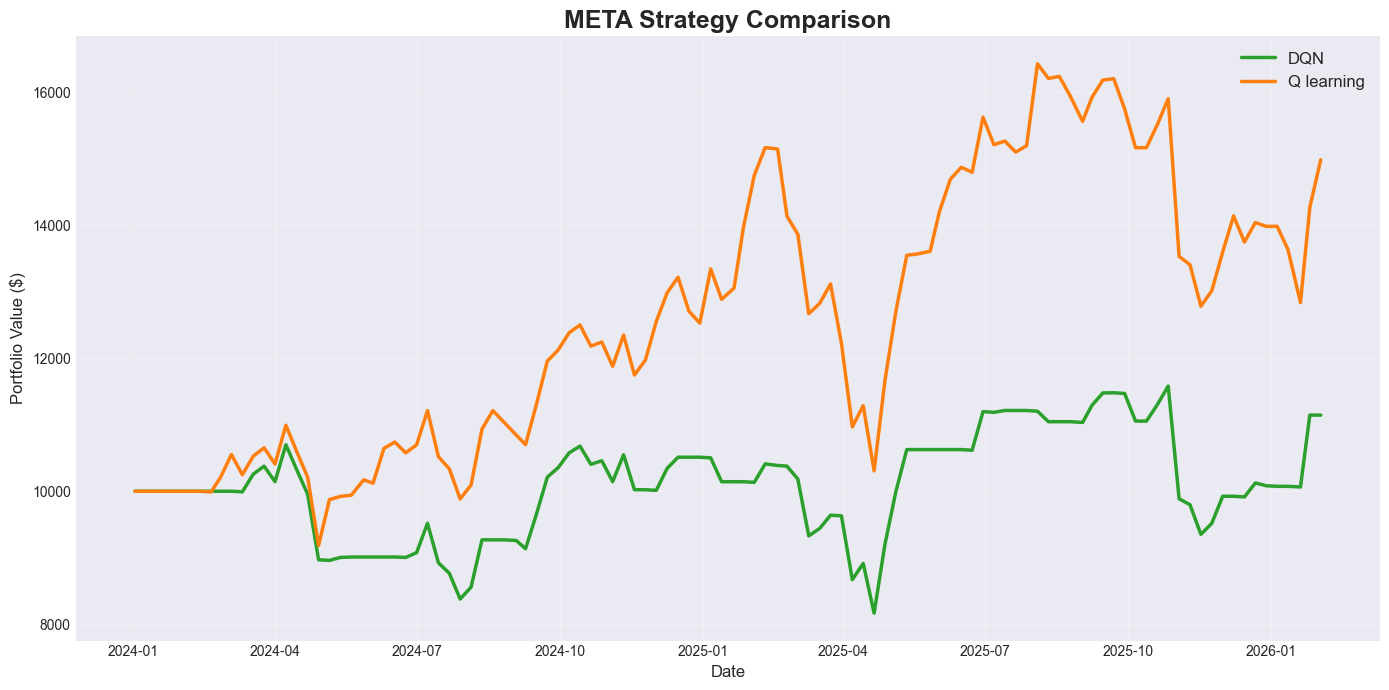

In [15]:
plot_ticker('META')

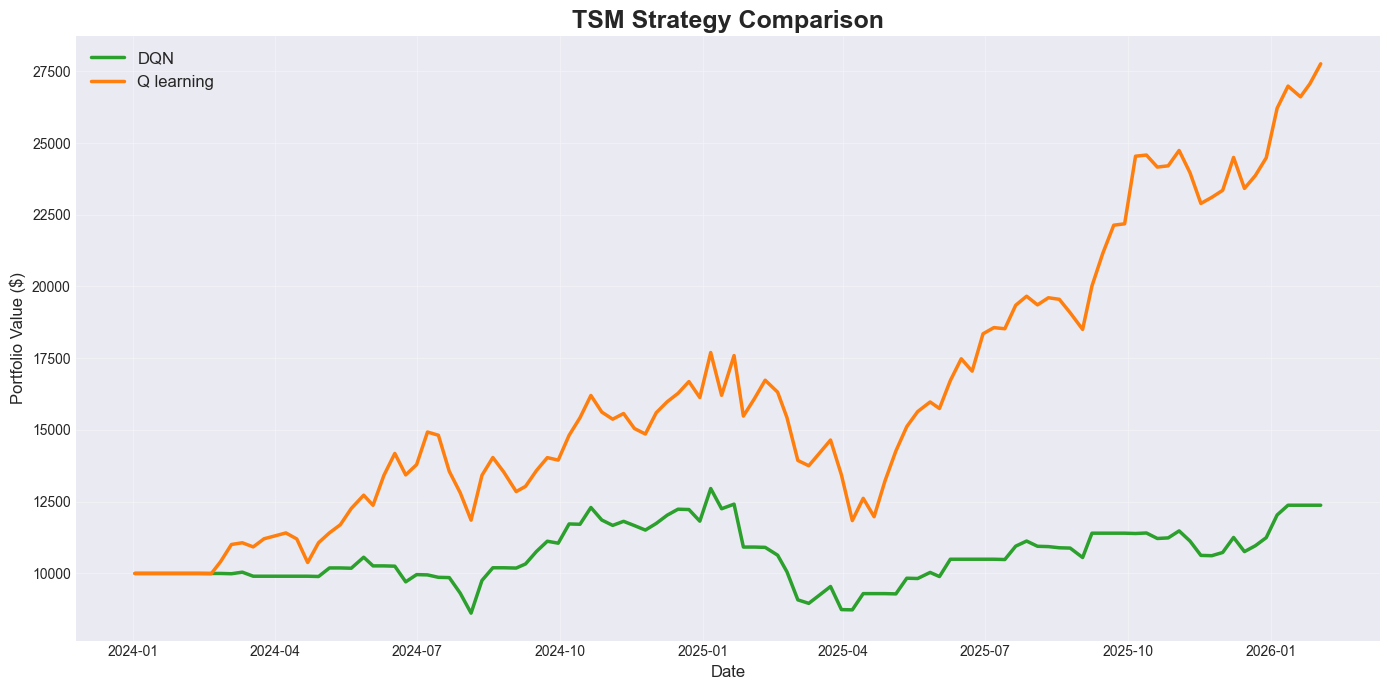

In [16]:
plot_ticker('TSM')

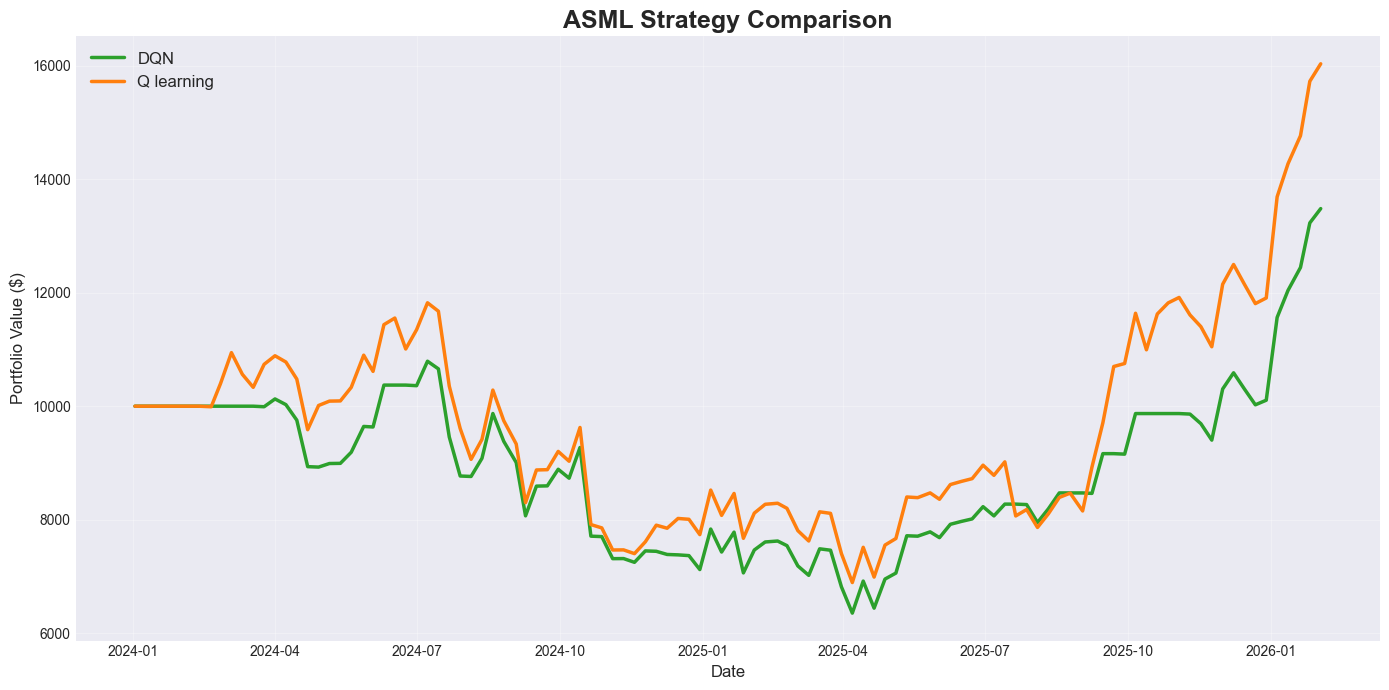

In [17]:
plot_ticker('ASML')